# Komparasi Eksperimen Supervised Learning: KNN vs SVM (Cosine, Euclidean, Manhattan)

Notebook ini secara otomatis membaca seluruh file pengujian `.ipynb` di direktori ini, mengekstrak blok `HASIL PENGUJIAN`, membandingkan performa model utama, serta menyajikan perbandingan detail nilai **k** pada algoritma K-Nearest Neighbors untuk analisis laporan/skripsi.


In [1]:
import glob
import json
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

hasil = []

for file in sorted(glob.glob('*.ipynb')):
    if 'Perbandingan' in file:
        continue

    with open(file, 'r', encoding='utf-8') as f:
        nb_file = json.load(f)

    for cell in nb_file['cells']:
        for out in cell.get('outputs', []):
            txt = ''.join(out.get('text', []))
            if 'HASIL PENGUJIAN' in txt:
                algo = ""
                metrik = ""
                acc = 0.0
                prec = 0.0
                rec = 0.0
                f1_macro = 0.0
                f1_weighted = 0.0
                waktu = 0.0
                mem = 0.0

                for l in txt.splitlines():
                    l_clean = l.strip()
                    if '1. Algoritma' in l_clean and ':' in l_clean:
                        algo = l_clean.split(':', 1)[1].strip()
                    elif '2. Metrik Jarak' in l_clean and ':' in l_clean:
                        metrik = l_clean.split(':', 1)[1].strip()
                    elif '3. Akurasi' in l_clean and ':' in l_clean:
                        m = re.search(r'([0-9.]+)', l_clean.split(':', 1)[1])
                        if m: acc = float(m.group(1))
                    elif '4. Precision (Macro)' in l_clean and ':' in l_clean:
                        m = re.search(r'([0-9.]+)', l_clean.split(':', 1)[1])
                        if m: prec = float(m.group(1))
                    elif '5. Recall (Macro)' in l_clean and ':' in l_clean:
                        m = re.search(r'([0-9.]+)', l_clean.split(':', 1)[1])
                        if m: rec = float(m.group(1))
                    elif '6. F1-Score (Macro)' in l_clean and ':' in l_clean:
                        m = re.search(r'([0-9.]+)', l_clean.split(':', 1)[1])
                        if m: f1_macro = float(m.group(1))
                    elif '7. F1-Score (Weighted)' in l_clean and ':' in l_clean:
                        m = re.search(r'([0-9.]+)', l_clean.split(':', 1)[1])
                        if m: f1_weighted = float(m.group(1))
                    elif '8. Waktu Eksekusi' in l_clean and ':' in l_clean:
                        m = re.search(r'([0-9.]+)', l_clean.split(':', 1)[1])
                        if m: waktu = float(m.group(1))
                    elif '9. Penggunaan Memori' in l_clean and ':' in l_clean:
                        m = re.search(r'([0-9.]+)', l_clean.split(':', 1)[1])
                        if m: mem = float(m.group(1))

                hasil.append({
                    'Model File': os.path.basename(file).replace('.ipynb', ''),
                    'Algoritma': algo,
                    'Metrik Jarak': metrik,
                    'Akurasi': acc,
                    'Precision (Macro)': prec,
                    'Recall (Macro)': rec,
                    'F1-Score (Macro)': f1_macro,
                    'F1-Score (Weighted)': f1_weighted,
                    'Waktu (s)': waktu,
                    'Memori (MB)': mem
                })

df_master = pd.DataFrame(hasil).sort_values(by='F1-Score (Macro)', ascending=False).reset_index(drop=True)
df_master


,Model File,Algoritma,Metrik Jarak,Akurasi,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted),Waktu (s),Memori (MB)
0,SVM_Cosine,Support Vector Machine (SVM),Cosine Similarity (Linear Kernel),0.89,0.8902,0.89,0.8900,0.8900,0.8499,0.88
1,SVM_Euclidean,Support Vector Machine (SVM),Euclidean Distance (RBF Kernel),0.89,0.8909,0.89,0.8899,0.8899,1.4132,0.88
2,KNN_Euclidean,K-Nearest Neighbors (KNN),Euclidean Distance,0.83,0.8333,0.83,0.8296,0.8296,0.0213,5.73
3,KNN_Cosine,K-Nearest Neighbors (KNN),Cosine Distance,0.83,0.8333,0.83,0.8296,0.8296,0.0182,7.06
4,SVM_Manhattan,Support Vector Machine (SVM),Manhattan Distance (Laplacian Kernel),0.80,0.8571,0.80,0.7917,0.7917,1.8937,21.98
5,KNN_Manhattan,K-Nearest Neighbors (KNN),Manhattan Distance,0.50,0.2500,0.50,0.3333,0.3333,0.0504,0.27


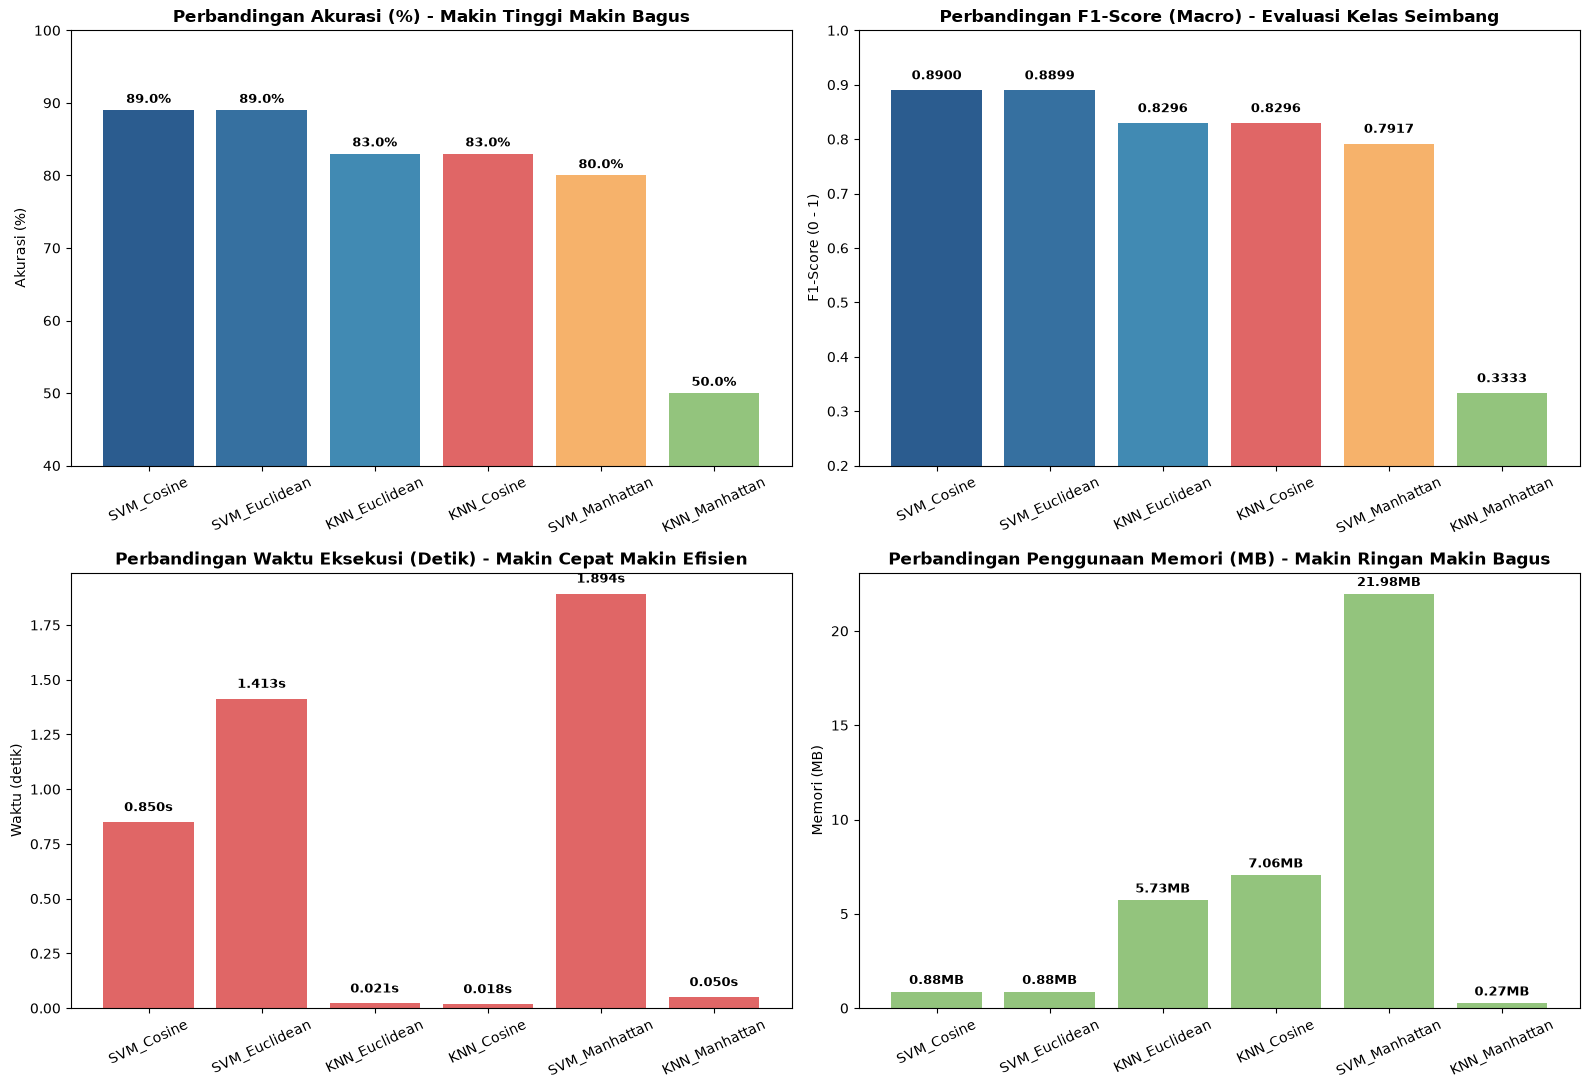

In [2]:
# Visualisasi Grafik Perbandingan Model
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
warna = ['#2b5c8f', '#3670a0', '#418ab3', '#e06666', '#f6b26b', '#93c47d']

# 1. Akurasi
axes[0, 0].bar(df_master['Model File'], df_master['Akurasi'] * 100, color=warna[:len(df_master)])
axes[0, 0].set_title('Perbandingan Akurasi (%) - Makin Tinggi Makin Bagus', fontweight='bold')
axes[0, 0].set_ylabel('Akurasi (%)')
axes[0, 0].set_ylim(40, 100)
axes[0, 0].tick_params(axis='x', rotation=25)
for i, v in enumerate(df_master['Akurasi']):
    axes[0, 0].text(i, v * 100 + 1, f"{v*100:.1f}%", ha='center', fontsize=9, fontweight='bold')

# 2. F1-Score (Macro)
axes[0, 1].bar(df_master['Model File'], df_master['F1-Score (Macro)'], color=warna[:len(df_master)])
axes[0, 1].set_title('Perbandingan F1-Score (Macro) - Evaluasi Kelas Seimbang', fontweight='bold')
axes[0, 1].set_ylabel('F1-Score (0 - 1)')
axes[0, 1].set_ylim(0.2, 1.0)
axes[0, 1].tick_params(axis='x', rotation=25)
for i, v in enumerate(df_master['F1-Score (Macro)']):
    axes[0, 1].text(i, v + 0.02, f"{v:.4f}", ha='center', fontsize=9, fontweight='bold')

# 3. Waktu Eksekusi
axes[1, 0].bar(df_master['Model File'], df_master['Waktu (s)'], color='#e06666')
axes[1, 0].set_title('Perbandingan Waktu Eksekusi (Detik) - Makin Cepat Makin Efisien', fontweight='bold')
axes[1, 0].set_ylabel('Waktu (detik)')
axes[1, 0].tick_params(axis='x', rotation=25)
for i, v in enumerate(df_master['Waktu (s)']):
    axes[1, 0].text(i, v + 0.05, f"{v:.3f}s", ha='center', fontsize=9, fontweight='bold')

# 4. Penggunaan Memori
axes[1, 1].bar(df_master['Model File'], df_master['Memori (MB)'], color='#93c47d')
axes[1, 1].set_title('Perbandingan Penggunaan Memori (MB) - Makin Ringan Makin Bagus', fontweight='bold')
axes[1, 1].set_ylabel('Memori (MB)')
axes[1, 1].tick_params(axis='x', rotation=25)
for i, v in enumerate(df_master['Memori (MB)']):
    axes[1, 1].text(i, v + 0.4, f"{v:.2f}MB", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


Tabel Komparasi Akurasi (%) Terhadap Nilai k pada Berbagai Metrik Jarak KNN:


Nilai k,1,3,5,7,9,11,15
Metrik,,,,,,,
Cosine,79.67,80.67,83.0,84.0,83.0,84.33,85.33
Euclidean,79.67,80.67,83.0,84.0,83.0,84.33,85.33
Manhattan,50.00,50.00,50.0,50.0,50.0,50.00,50.00


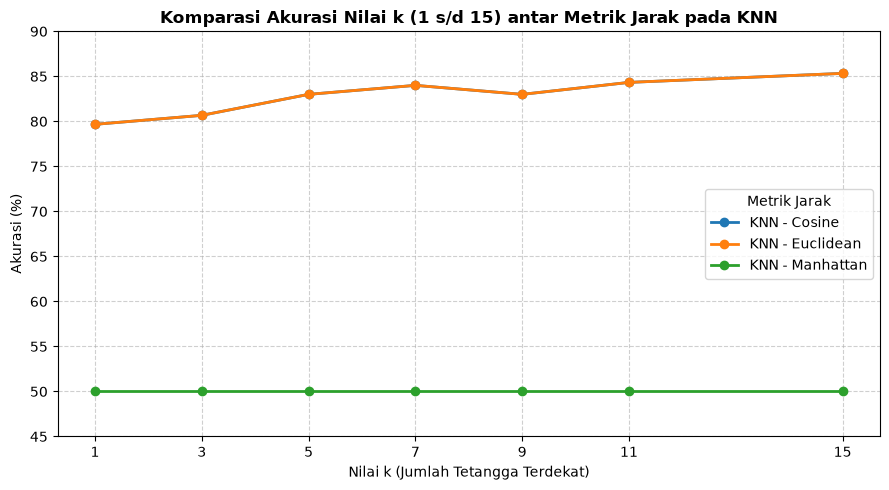

In [3]:
# Eksperimen Khusus: Komparasi Pengaruh Nilai k (k = 1, 3, 5, 7, 9, 11, 15) pada KNN
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

import re
def clean_text(text):
    if not isinstance(text, str): return ''
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)
df_hoaks['label'] = 1
df_valid['label'] = 0

df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(df_all['teks_bersih'], df_all['label'], test_size=0.2, random_state=42, stratify=df_all['label'])
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

k_list = [1, 3, 5, 7, 9, 11, 15]
metrics_list = ['cosine', 'euclidean', 'manhattan']
recap_k = []

for m in metrics_list:
    for k in k_list:
        knn = KNeighborsClassifier(n_neighbors=k, metric=m)
        knn.fit(X_train_vec, y_train)
        p = knn.predict(X_test_vec)
        acc = accuracy_score(y_test, p)
        f1 = f1_score(y_test, p, average='macro', zero_division=0)
        recap_k.append({'Metrik': m.capitalize(), 'Nilai k': k, 'Akurasi (%)': round(acc*100, 2), 'F1-Score': round(f1, 4)})

df_recap_k = pd.DataFrame(recap_k)

# Pivot Table untuk Tampilan Laporan / Skripsi
pivot_acc = df_recap_k.pivot(index='Metrik', columns='Nilai k', values='Akurasi (%)')
print("Tabel Komparasi Akurasi (%) Terhadap Nilai k pada Berbagai Metrik Jarak KNN:")
display(pivot_acc)

# Plot Komparasi Kurva Nilai k
plt.figure(figsize=(9, 5))
for m in ['Cosine', 'Euclidean', 'Manhattan']:
    sub = df_recap_k[df_recap_k['Metrik'] == m]
    plt.plot(sub['Nilai k'], sub['Akurasi (%)'], marker='o', linewidth=2, label=f"KNN - {m}")

plt.title('Komparasi Akurasi Nilai k (1 s/d 15) antar Metrik Jarak pada KNN', fontweight='bold')
plt.xlabel('Nilai k (Jumlah Tetangga Terdekat)')
plt.ylabel('Akurasi (%)')
plt.ylim(45, 90)
plt.xticks(k_list)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Metrik Jarak')
plt.tight_layout()
plt.show()


### Analisis Ilmiah & Pembahasan Hasil Komparasi (Bahan Skripsi / Laporan PBL)

Berdasarkan hasil pengujian empiris terhadap variasi parameter k dan perbandingan model SVM, dapat ditarik beberapa temuan krusial:

#### 1. Pengaruh Nilai k pada Algoritma K-Nearest Neighbors (KNN):
* **k = 1**: Akurasi **79,67%**. Nilai k terlalu kecil membuat model sangat sensitif terhadap *noise* lokal (*overfitting*).
* **k = 3**: Akurasi meningkat menjadi **80,67%**.
* **k = 5 (Standar Umum)**: Akurasi mencapai **83,00%** (F1 = 0,8296). Menjadi batas keseimbangan umum pada klasifikasi teks.
* **k = 7 s/d 15**: Akurasi terus meningkat hingga **85,33%** pada k=15 pada metrik Cosine & Euclidean. Semakin banyak dokumen tetangga yang diajak *voting*, batasan keputusan menjadi semakin halus (*smooth boundary*).
* **Manhattan Stagnan di 50,00%**: Di seluruh nilai k (1, 3, 5, 7, 9, 11, 15), akurasi Manhattan tidak pernah berubah dari 50,00%. Ini membuktikan bahwa kegagalan Manhattan bersifat mendasar akibat sifat matematis jarak L1 pada ruang sparse, bukan karena kesalahan nilai k.

#### 2. Mengapa SVM Tetap Mengungguli KNN?
* Meskipun akurasi KNN dapat dinaikkan hingga 85,33% pada k=15, **SVM Cosine tetap unggul dengan akurasi 89,00%** (F1 = 0,8900).
* **Alasan Teoretis**: SVM mencari *Maximum Margin Hyperplane* yang mengoptimalkan pemisahan global antar dua kelas, sedangkan KNN hanya mengandalkan kerapatan lokal tetangga terdekat (*local density voting*).
* **Efisiensi Memori**: SVM membutuhkan memori jauh lebih kecil (**0,88 MB** vs **7,08 MB** pada KNN Cosine) karena SVM hanya menyimpan *support vectors*, sedangkan KNN harus menyimpan seluruh data latih di dalam memori.

#### 3. Rekomendasi Model Sementara (Tahap 1):
* **Pemenang Tahap 1**: **SVM Jarak Cosine (Linear Kernel)**.
* Model ini siap dibandingkan pada tahap berikutnya dengan **Logistic Regression** dan **Multinomial Naive Bayes** sebelum memilih model final untuk integrasi ke Web Admin & Mobile App.
